# Clasificación supervisada de relevancia de memorias en conversaciones de largo plazo

**Proyecto final · Aprendizaje Supervisado · Maestría en Inteligencia Artificial, USFQ**

**Autor:** Roberth Chachalo

## 1. Introducción

Un agente conversacional que acompaña a una persona durante meses acumula cientos de *memorias*: cosas que el usuario contó en charlas pasadas. Cuando llega una pregunta nueva, el agente no puede releer toda la historia, así que debe decidir **qué memorias traer** para responder.

La solución habitual es la búsqueda por similitud: se convierte la pregunta y cada memoria en un vector (*embedding*) y se traen las memorias cuyos vectores están más cerca del vector de la pregunta. El problema es que **parecerse a la pregunta no es lo mismo que contener la respuesta**. Ante la pregunta *«When did Caroline go to the LGBTQ support group?»*, estas dos memorias son muy parecidas a la pregunta:

- *«I went to a LGBTQ support group yesterday and it was so powerful.»* → contiene la respuesta.
- *«The support group has made me feel accepted and given me courage to embrace myself.»* → habla del mismo tema, pero no dice cuándo.

Este proyecto plantea esa decisión como un problema de **clasificación binaria supervisada**: dado un par *(pregunta, memoria candidata)*, predecir si la memoria contiene evidencia para responder la pregunta. El clasificador no usa solo la similitud, sino un conjunto de señales semánticas, léxicas, temporales y de contexto, y se compara contra la línea base de usar únicamente la similitud coseno.

El trabajo sigue este flujo:

1. Cada pregunta de LoCoMo y todos los turnos de su conversación se convierten en embeddings.
2. *Retrieval*: se toman los 20 turnos con mayor similitud coseno (los candidatos).
3. Etiqueta: 1 si el turno está en la evidencia anotada de la pregunta, 0 si no.
4. Por cada par se calculan 14 columnas numéricas (*features*).
5. El clasificador aprende con unas preguntas y se evalúa con preguntas que nunca vio.

El notebook está organizado así:

- **Secciones 2 a 5:** los datos, la extracción de características con un modelo preentrenado, la construcción de la tabla de pares y la forma de separar los datos sin fuga de información.
- **Secciones 6 y 7:** análisis exploratorio y visualización del espacio de features con t-SNE.
- **Secciones 8 y 9:** pipelines, selección de features, optimización de hiperparámetros y comparación estadística de los dos modelos.
- **Sección 10:** conclusiones.

## 2. Los datos: LoCoMo

LoCoMo [1] es un benchmark público de memoria conversacional de muy largo plazo. Contiene 10 conversaciones entre dos personas, cada una repartida en muchas sesiones a lo largo de varios meses, y 1.986 preguntas sobre lo que se dijo en ellas. Los datos están en inglés y se dejan en su idioma original.

### Vocabulario

| Término | Qué es | Ejemplo |
|---|---|---|
| **Conversación** | Toda la historia entre dos personas. Hay 10. | Caroline y Melanie |
| **Sesión** | Una charla en una fecha concreta. Cada conversación tiene entre 19 y 32. | Sesión 1: 8 de mayo de 2023 |
| **Turno** | **Un mensaje de una persona.** Cada vez que alguien habla es un turno. | `D1:3` = sesión 1, mensaje número 3 |
| **Pregunta** | Una consulta sobre la conversación, con su respuesta. | *When did Caroline go to the LGBTQ support group?* |
| **Evidencia** | Lista de turnos donde está la respuesta, anotada por humanos. | `["D1:3"]` |

En este proyecto, **cada turno es una memoria candidata**: es la unidad mínima que el agente puede recuperar.

In [1]:
# En Google Colab, descomentar las tres líneas siguientes. Clonan el repositorio, que incluye en data/
# los embeddings ya calculados (en Colab no hay Ollama), e instalan la única dependencia que falta.
# !git clone https://github.com/betochalo/relevancia-memorias-locomo.git
# %cd relevancia-memorias-locomo
# !pip install -q rank-bm25

import hashlib
import json
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

SEMILLA = 42
N_PREGUNTAS = 500        # tamaño de la muestra de preguntas
K_CANDIDATOS = 20        # turnos recuperados por pregunta
MODELO_EMBEDDINGS = "qwen3-embedding:0.6b"   # modelo de embeddings servido localmente con Ollama
URL_OLLAMA = "http://localhost:11434/api/embed"

DIR_DATOS = Path("data")
RUTA_LOCOMO = DIR_DATOS / "locomo10.json"
RUTA_PARES = DIR_DATOS / "pares.csv"
RUTA_EMBEDDINGS = DIR_DATOS / "embeddings.npz"
URL_LOCOMO = "https://raw.githubusercontent.com/snap-research/locomo/main/data/locomo10.json"

pd.set_option("display.max_colwidth", 90)

In [2]:
# Descarga el archivo solo si no existe (así el notebook corre igual en Colab).
DIR_DATOS.mkdir(exist_ok=True)
if not RUTA_LOCOMO.exists():
    urllib.request.urlretrieve(URL_LOCOMO, RUTA_LOCOMO)

with open(RUTA_LOCOMO, encoding="utf-8") as f:
    locomo = json.load(f)

print("Conversaciones:", len(locomo))
print("Preguntas:", sum(len(c["qa"]) for c in locomo))

Conversaciones: 10
Preguntas: 1986


### 2.1 Tabla de turnos

Se recorre cada conversación y se guarda una fila por turno. El campo `dia_id` identifica al turno dentro de su conversación (`D1:3` = sesión 1, turno 3). Se añade `pos`, la posición global del turno en la conversación (0 para el primer mensaje), que después permite ubicar al turno anterior y al siguiente.

Algunos turnos incluyen una imagen con una descripción automática (`blip_caption`). Aquí se usa solo el texto escrito por el hablante.

In [3]:
filas = []
for conv in locomo:
    c = conv["conversation"]
    sesiones = sorted(int(k.split("_")[1]) for k in c if re.fullmatch(r"session_\d+", k))
    pos = 0
    for n in sesiones:
        for turno in c[f"session_{n}"]:
            filas.append({
                "id_conversacion": conv["sample_id"],
                "dia_id": turno["dia_id"],
                "n_sesion": n,
                "fecha_sesion": c.get(f"session_{n}_date_time", ""),
                "pos": pos,
                "hablante": turno["speaker"],
                "texto": turno["text"],
            })
            pos += 1

turnos = pd.DataFrame(filas)
# Posición relativa del turno dentro de su conversación, de 0 (inicio) a 1 (final).
turnos["pos_relativa"] = turnos["pos"] / turnos.groupby("id_conversacion")["pos"].transform("max")

print("Turnos (memorias candidatas):", len(turnos))
turnos.groupby("id_conversacion").agg(
    hablantes=("hablante", lambda s: " y ".join(sorted(s.unique()))),
    sesiones=("n_sesion", "nunique"),
    turnos=("dia_id", "size"),
)

Turnos (memorias candidatas): 5882


,hablantes,sesiones,turnos
id_conversacion,,,
conv-26,Caroline y Melanie,19,419
conv-30,Gina y Jon,19,369
conv-41,John y Maria,32,663
conv-42,Joanna y Nate,29,629
conv-43,John y Tim,29,680
conv-44,Andrew y Audrey,28,675
conv-47,James y John,31,689
conv-48,Deborah y Jolene,30,681
conv-49,Evan y Sam,25,509


In [4]:
# Los primeros turnos de la primera conversación: así se ve una charla.
turnos.loc[turnos["id_conversacion"] == "conv-26",
           ["dia_id", "fecha_sesion", "hablante", "texto"]].head(6)

,dia_id,fecha_sesion,hablante,texto
0,D1:1,"1:56 pm on 8 May, 2023",Caroline,Hey Mel! Good to see you! How have you been?
1,D1:2,"1:56 pm on 8 May, 2023",Melanie,Hey Caroline! Good to see you! I'm swamped with the kids & work. What's up with you? A...
2,D1:3,"1:56 pm on 8 May, 2023",Caroline,I went to a LGBTQ support group yesterday and it was so powerful.
3,D1:4,"1:56 pm on 8 May, 2023",Melanie,"Wow, that's cool, Caroline! What happened that was so awesome? Did you hear any inspir..."
4,D1:5,"1:56 pm on 8 May, 2023",Caroline,The transgender stories were so inspiring! I was so happy and thankful for all the sup...
5,D1:6,"1:56 pm on 8 May, 2023",Melanie,"Wow, love that painting! So cool you found such a helpful group. What's it done for you?"


### 2.2 Tabla de preguntas

Cada pregunta trae su categoría y su lista de evidencia. Se toman tres decisiones:

- **Se excluye la categoría adversarial (5).** Son preguntas sin respuesta en la conversación, así que su «evidencia» no representa una memoria útil.
- **Se limpia la evidencia.** Unas pocas anotaciones vienen mal formadas (por ejemplo `"D8:6; D9:17"` en una sola cadena) o apuntan a turnos que no existen. Se extraen los identificadores válidos con una expresión regular y se descartan las preguntas que quedan sin evidencia.
- **Se toma una muestra aleatoria de 500 preguntas**, suficiente para el estudio y rápida de procesar.

La categoría se conserva **solo para el análisis exploratorio**; no se usa como feature porque un sistema real no la conoce de antemano.

In [5]:
CATEGORIAS = {1: "multisalto", 2: "temporal", 3: "dominio abierto", 4: "un salto", 5: "adversarial"}

ids_validos = {cid: set(g["dia_id"]) for cid, g in turnos.groupby("id_conversacion")}

filas = []
for conv in locomo:
    cid = conv["sample_id"]
    for i, qa in enumerate(conv["qa"]):
        crudo = " ".join(qa.get("evidence", []))
        evidencia = sorted(set(re.findall(r"D\d+:\d+", crudo)) & ids_validos[cid])
        filas.append({
            "id_pregunta": f"{cid}_q{i:03d}",
            "id_conversacion": cid,
            "pregunta": qa["question"],
            "categoria": CATEGORIAS[qa["category"]],
            "evidencia": evidencia,
        })

todas = pd.DataFrame(filas)
validas = todas[(todas["categoria"] != "adversarial") & (todas["evidencia"].str.len() > 0)]
preguntas = validas.sample(N_PREGUNTAS, random_state=SEMILLA).sort_values("id_pregunta").reset_index(drop=True)

print(f"Preguntas totales: {len(todas)} | no adversariales y con evidencia: {len(validas)} | muestra: {len(preguntas)}")
pd.DataFrame({
    "disponibles": validas["categoria"].value_counts(),
    "muestra": preguntas["categoria"].value_counts(),
})

Preguntas totales: 1986 | no adversariales y con evidencia: 1535 | muestra: 500


,disponibles,muestra
categoria,,
un salto,841,279
temporal,320,102
multisalto,282,98
dominio abierto,92,21


In [6]:
preguntas.head()

,id_pregunta,id_conversacion,pregunta,categoria,evidencia
0,conv-26_q010,conv-26,How long has Caroline had her current group of friends for?,temporal,[D3:13]
1,conv-26_q015,conv-26,What activities does Melanie partake in?,multisalto,"[D1:12, D1:18, D5:4, D9:1]"
2,conv-26_q018,conv-26,Where has Melanie camped?,multisalto,"[D4:6, D6:16, D8:32]"
3,conv-26_q023,conv-26,What books has Melanie read?,multisalto,"[D6:10, D7:8]"
4,conv-26_q029,conv-26,When did Melanie go to the pottery workshop?,temporal,[D8:2]


## 3. Extracción de características con un modelo preentrenado

Para medir cuánto se parece una pregunta a un turno se usa **Qwen3-Embedding-0.6B** [2], un modelo de *embeddings* de texto preentrenado. Convierte cada texto en un vector de 1.024 números, de modo que textos con significado parecido quedan cerca. Es **transfer learning**: el modelo se entrenó en otra tarea y aquí no se reentrena, solo se aprovechan sus representaciones.

El modelo se ejecuta de forma local con Ollama (`ollama pull qwen3-embedding:0.6b`). Como calcular los embeddings de todos los turnos tarda varios minutos en CPU, el resultado se guarda en `data/` y en las siguientes ejecuciones se lee del archivo. Gracias a ese archivo el notebook también corre donde no hay Ollama, por ejemplo en Colab.

Los vectores se normalizan a longitud 1, de modo que la similitud coseno entre dos textos es simplemente su producto punto.

### El turno se representa como «hablante: texto»

Las preguntas nombran a la persona (*«When did Melanie make a plate in pottery class?»*), pero quien responde habla en primera persona y no se nombra (*«I made this plate...»*). Si se representa solo el texto, el modelo trae los mensajes que *mencionan* a Melanie, es decir, los que le dirige la otra persona, y no los que ella dijo. Por eso cada turno se representa con el nombre de quien habla por delante, un dato que un agente real siempre conoce.

Una prueba previa en dos conversaciones (231 preguntas) mostró cuánto pesa esta decisión. La tabla indica el porcentaje de preguntas con al menos un turno de evidencia entre los 20 candidatos:

| Representación del turno | BGE-M3 | Qwen3-Embedding-0.6B |
|---|---|---|
| Solo el texto | 16,9% | 36,4% |
| `hablante: texto` | 74,9% | 82,3% |

Como referencia, BM25 solo alcanza 59,7%. Se eligió Qwen3-Embedding con `hablante: texto`.

Los embeddings **no entran a la tabla final**: son un paso intermedio para calcular features como `sim_coseno`.

In [7]:
def embeber_con_ollama(textos, lote=32):
    # Pide los embeddings a Ollama por lotes y los normaliza a longitud 1.
    vectores = []
    for i in range(0, len(textos), lote):
        cuerpo = json.dumps({"model": MODELO_EMBEDDINGS, "input": textos[i:i + lote]}).encode()
        peticion = urllib.request.Request(URL_OLLAMA, data=cuerpo,
                                          headers={"Content-Type": "application/json"})
        with urllib.request.urlopen(peticion, timeout=600) as respuesta:
            vectores.extend(json.load(respuesta)["embeddings"])
    E = np.asarray(vectores, dtype=np.float32)
    return E / np.linalg.norm(E, axis=1, keepdims=True)


def embeber(textos_turnos, textos_preguntas):
    # La huella identifica el modelo y los textos: si cambia la muestra, se recalcula.
    huella = hashlib.sha1("\n".join([MODELO_EMBEDDINGS] + textos_turnos + textos_preguntas).encode()).hexdigest()
    if RUTA_EMBEDDINGS.exists():
        guardado = np.load(RUTA_EMBEDDINGS)
        if str(guardado["huella"]) == huella:
            print("Embeddings leídos de", RUTA_EMBEDDINGS)
            return guardado["turnos"].astype(np.float32), guardado["preguntas"].astype(np.float32)
    print("Calculando embeddings con Ollama (tarda varios minutos en CPU)...")
    E_t, E_p = embeber_con_ollama(textos_turnos), embeber_con_ollama(textos_preguntas)
    # float16 reduce el archivo a la mitad sin afectar las similitudes.
    np.savez_compressed(RUTA_EMBEDDINGS, turnos=E_t.astype(np.float16),
                        preguntas=E_p.astype(np.float16), huella=huella)
    return E_t, E_p


# Cada turno se representa como "hablante: texto".
textos_turnos = (turnos["hablante"] + ": " + turnos["texto"]).tolist()
emb_turnos, emb_preguntas = embeber(textos_turnos, preguntas["pregunta"].tolist())

print("Embeddings de turnos:   ", emb_turnos.shape)
print("Embeddings de preguntas:", emb_preguntas.shape)

Embeddings leídos de data/embeddings.npz
Embeddings de turnos:    (5882, 1024)
Embeddings de preguntas: (500, 1024)


## 4. Construcción de la tabla de pares

Para cada pregunta:

1. Se calcula su similitud coseno con **todos** los turnos de su conversación.
2. Se conservan los 20 turnos más similares: los candidatos.
3. Cada candidato recibe etiqueta 1 si su `dia_id` está en la evidencia de la pregunta y 0 si no.
4. Se calculan las features del par.

| Feature | Qué mide | Tipo de señal |
|---|---|---|
| `sim_coseno` | Similitud entre los embeddings de la pregunta y el turno | Semántica |
| `rank_coseno` | Posición del turno entre los 20 candidatos (1 = el más similar) | Semántica |
| `brecha_top1` | Similitud del mejor candidato menos la de este turno | Semántica |
| `sim_z` | Similitud estandarizada dentro de los 20 candidatos de la pregunta | Semántica |
| `bm25` | Puntaje BM25 [3] de la pregunta contra el turno | Léxica |
| `jaccard` | Proporción de palabras compartidas (sin palabras vacías) | Léxica |
| `n_clave_comunes` | Nombres propios y números de la pregunta que aparecen en el turno | Léxica |
| `menciona_hablante` | 1 si la pregunta nombra a quien dijo el turno | Léxica |
| `len_turno`, `len_pregunta` | Número de palabras de cada texto | Estructura |
| `pos_relativa` | Posición del turno en la conversación, de 0 a 1 | Temporal |
| `n_sesion` | Número de sesión del turno | Temporal |
| `sim_vecinos` | Similitud media de la pregunta con los turnos anterior y siguiente | Contexto |
| `redundancia` | Máxima similitud del turno con los candidatos mejor rankeados | Contexto |

Ninguna feature usa la respuesta, la evidencia ni la categoría: todas se pueden calcular en un sistema real en el momento de la consulta.

In [8]:
def tokenizar(texto):
    # Palabras en minúsculas, solo letras y números.
    return re.findall(r"[a-z0-9]+", texto.lower())


def palabras_contenido(texto):
    # Conjunto de palabras sin palabras vacías ("the", "did", "to"...).
    return {t for t in tokenizar(texto) if t not in ENGLISH_STOP_WORDS}


def terminos_clave(pregunta):
    # Nombres propios (palabras con mayúscula que no inician la pregunta) y números.
    palabras = re.findall(r"[A-Za-z0-9]+", pregunta)
    clave = {p.lower() for p in palabras[1:] if p[0].isupper()}
    clave |= {p for p in palabras if p.isdigit()}
    return clave


def construir_pares(preguntas, turnos, emb_preguntas, emb_turnos, k=K_CANDIDATOS):
    filas = []
    for cid, pregs_conv in preguntas.groupby("id_conversacion"):
        t = turnos[turnos["id_conversacion"] == cid]          # turnos en orden de conversación
        E = emb_turnos[t.index.to_numpy()]                    # (n_turnos, 1024)
        tokens_turnos = [tokenizar(x) for x in t["texto"]]
        bm25 = BM25Okapi(tokens_turnos)                       # índice léxico de la conversación
        n = len(t)

        for iq, p in pregs_conv.iterrows():
            sims = E @ emb_preguntas[iq]                      # similitud con todos los turnos
            top = np.argsort(-sims)[:k]                       # índices de los k más similares
            s_top = sims[top]
            puntajes_bm25 = bm25.get_scores(tokenizar(p["pregunta"]))
            sim_entre_candidatos = E[top] @ E[top].T

            contenido_p = palabras_contenido(p["pregunta"])
            clave_p = terminos_clave(p["pregunta"])
            tokens_p = set(tokenizar(p["pregunta"]))
            evidencia = set(p["evidencia"])

            for r, j in enumerate(top):
                turno = t.iloc[j]
                contenido_t = palabras_contenido(turno["texto"])
                union = contenido_p | contenido_t
                vecinos = [sims[v] for v in (j - 1, j + 1) if 0 <= v < n]
                filas.append({
                    "id_pregunta": p["id_pregunta"],
                    "id_conversacion": cid,
                    "categoria": p["categoria"],
                    "dia_id": turno["dia_id"],
                    "pregunta": p["pregunta"],
                    "hablante": turno["hablante"],
                    "texto_turno": turno["texto"],
                    # --- semánticas ---
                    "sim_coseno": s_top[r],
                    "rank_coseno": r + 1,
                    "brecha_top1": s_top[0] - s_top[r],
                    "sim_z": (s_top[r] - s_top.mean()) / s_top.std(),
                    # --- léxicas ---
                    "bm25": puntajes_bm25[j],
                    "jaccard": len(contenido_p & contenido_t) / len(union) if union else 0.0,
                    "n_clave_comunes": len(clave_p & set(tokens_turnos[j])),
                    "menciona_hablante": int(turno["hablante"].lower() in tokens_p),
                    # --- estructura ---
                    "len_turno": len(tokens_turnos[j]),
                    "len_pregunta": len(tokenizar(p["pregunta"])),
                    # --- temporales ---
                    "pos_relativa": turno["pos_relativa"],
                    "n_sesion": turno["n_sesion"],
                    # --- contexto ---
                    "sim_vecinos": float(np.mean(vecinos)),
                    "redundancia": sim_entre_candidatos[r, :r].max() if r > 0 else 0.0,
                    # --- etiqueta ---
                    "relevante": int(turno["dia_id"] in evidencia),
                })
    return pd.DataFrame(filas)


pares = construir_pares(preguntas, turnos, emb_preguntas, emb_turnos)
print(pares.shape)
pares.head()

(10000, 22)


,id_pregunta,id_conversacion,categoria,dia_id,pregunta,hablante,texto_turno,sim_coseno,rank_coseno,brecha_top1,...,jaccard,n_clave_comunes,menciona_hablante,len_turno,len_pregunta,pos_relativa,n_sesion,sim_vecinos,redundancia,relevante
0,conv-26_q010,conv-26,temporal,D3:13,How long has Caroline had her current group of friends for?,Caroline,"Yeah, I'm really lucky to have them. They've been there through everything, I've known...",0.676121,1,0.000000,...,0.038462,0,1,50,11,0.112440,3,0.497051,0.000000,1
1,conv-26_q010,conv-26,temporal,D14:14,How long has Caroline had her current group of friends for?,Melanie,"Caroline, glad you found a supportive community! Can you tell me more about why it's s...",0.652183,2,0.023937,...,0.090909,1,0,19,11,0.679426,14,0.452700,0.640581,0
2,conv-26_q010,conv-26,temporal,D3:15,How long has Caroline had her current group of friends for?,Caroline,"Wow, what an amazing family pic! How long have you been married?",0.641356,3,0.034765,...,0.100000,0,1,12,11,0.117225,3,0.499567,0.528096,0
3,conv-26_q010,conv-26,temporal,D4:10,How long has Caroline had her current group of friends for?,Melanie,"Thanks, Caroline! Family time matters to me. What's up with you lately?",0.628732,4,0.047389,...,0.090909,1,0,13,11,0.160287,4,0.500587,0.777642,0
4,conv-26_q010,conv-26,temporal,D12:14,How long has Caroline had her current group of friends for?,Melanie,"I appreciate our friendship too, Caroline. You've always been there for me.",0.618497,5,0.057624,...,0.125000,1,0,13,11,0.586124,12,0.568314,0.762901,0


### 4.1 Un ejemplo completo

Los 20 candidatos de una pregunta, ordenados por similitud. Se ve el problema que motiva el proyecto: varios turnos se parecen a la pregunta, pero solo los marcados con `relevante = 1` contienen la respuesta.

In [9]:
ejemplo = pares[pares["id_pregunta"] == pares.loc[pares["relevante"] == 1, "id_pregunta"].iloc[0]]
print("Pregunta:", ejemplo["pregunta"].iloc[0])
ejemplo[["rank_coseno", "dia_id", "hablante", "texto_turno", "sim_coseno", "bm25", "relevante"]].head(8)

Pregunta: How long has Caroline had her current group of friends for?


,rank_coseno,dia_id,hablante,texto_turno,sim_coseno,bm25,relevante
0,1,D3:13,Caroline,"Yeah, I'm really lucky to have them. They've been there through everything, I've known...",0.676121,3.338758,1
1,2,D14:14,Melanie,"Caroline, glad you found a supportive community! Can you tell me more about why it's s...",0.652183,0.918699,0
2,3,D3:15,Caroline,"Wow, what an amazing family pic! How long have you been married?",0.641356,6.603451,0
3,4,D4:10,Melanie,"Thanks, Caroline! Family time matters to me. What's up with you lately?",0.628732,1.041952,0
4,5,D12:14,Melanie,"I appreciate our friendship too, Caroline. You've always been there for me.",0.618497,2.418175,0
5,6,D8:38,Melanie,"Thanks, Caroline! Appreciate your friendship. It's great to have a supporter!",0.614993,1.065784,0
6,7,D1:7,Caroline,The support group has made me feel accepted and given me courage to embrace myself.,0.608190,8.595441,0
7,8,D10:6,Melanie,"Wow, Caroline, your group sounds awesome! Supporting each other and making good things...",0.605680,5.611765,0


### 4.2 Resumen y guardado

Se revisan tres cosas antes de guardar:

- **Tasa de positivos**: qué fracción de los pares es relevante (el desbalance de clases).
- **Recall del retrieval**: en qué fracción de las preguntas al menos un turno de evidencia cayó en el top-20. Las preguntas donde no cayó ninguno aportan solo ceros; se conservan, porque así es el problema real, y se reporta cuántas son.
- **Valores faltantes**: no debe haber ninguno.

In [10]:
FEATURES = ["sim_coseno", "rank_coseno", "brecha_top1", "sim_z", "bm25", "jaccard",
            "n_clave_comunes", "menciona_hablante", "len_turno", "len_pregunta",
            "pos_relativa", "n_sesion", "sim_vecinos", "redundancia"]

positivos_por_pregunta = pares.groupby("id_pregunta")["relevante"].sum()
total_evidencia = preguntas["evidencia"].str.len().sum()

print(f"Filas: {len(pares)} | preguntas: {pares['id_pregunta'].nunique()} | features: {len(FEATURES)}")
print(f"Pares relevantes: {pares['relevante'].sum()} ({pares['relevante'].mean():.1%})")
print(f"Preguntas con al menos un positivo en el top-{K_CANDIDATOS}: "
      f"{(positivos_por_pregunta > 0).sum()} de {len(positivos_por_pregunta)} "
      f"({(positivos_por_pregunta > 0).mean():.1%})")
print(f"Preguntas sin ningún positivo: {(positivos_por_pregunta == 0).sum()}")
print(f"Turnos de evidencia recuperados: {pares['relevante'].sum()} de {total_evidencia} "
      f"({pares['relevante'].sum() / total_evidencia:.1%})")
print("Valores faltantes:", int(pares.isna().sum().sum()))

pares.to_csv(RUTA_PARES, index=False)
print("Tabla guardada en", RUTA_PARES)

Filas: 10000 | preguntas: 500 | features: 14
Pares relevantes: 514 (5.1%)
Preguntas con al menos un positivo en el top-20: 416 de 500 (83.2%)
Preguntas sin ningún positivo: 84
Turnos de evidencia recuperados: 514 de 796 (64.6%)
Valores faltantes: 0
Tabla guardada en data/pares.csv


In [11]:
pares[FEATURES + ["relevante"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
sim_coseno,10000.0,0.619,0.072,0.381,0.569,0.616,0.667,0.903
rank_coseno,10000.0,10.500,5.767,1.000,5.750,10.500,15.250,20.000
brecha_top1,10000.0,0.100,0.063,0.000,0.054,0.093,0.139,0.325
sim_z,10000.0,-0.000,1.000,-1.748,-0.696,-0.302,0.415,4.117
bm25,10000.0,3.384,3.535,0.000,0.640,2.630,4.851,36.378
jaccard,10000.0,0.056,0.062,0.000,0.000,0.050,0.087,0.600
n_clave_comunes,10000.0,0.331,0.500,0.000,0.000,0.000,1.000,3.000
menciona_hablante,10000.0,0.760,0.427,0.000,1.000,1.000,1.000,1.000
len_turno,10000.0,24.215,13.160,1.000,14.000,22.000,32.000,90.000
len_pregunta,10000.0,10.248,3.255,3.000,8.000,10.000,12.000,25.000


## 5. Cómo separar los datos sin fuga de información

La tabla tiene unas 10.000 filas, pero **no son 10.000 ejemplos independientes**: las 20 filas de una misma pregunta comparten la pregunta y varias features se calculan *dentro* de ese grupo (`rank_coseno`, `sim_z`, `brecha_top1`, `redundancia`).

Si se reparten las filas al azar, 18 candidatos de una pregunta pueden quedar en entrenamiento y los otros 2 en prueba. El modelo ya vio esa pregunta, y con ella pistas de cuáles de sus candidatos son positivos. El puntaje sale inflado y no mide lo que interesa: cómo responde el modelo ante **preguntas nuevas**. Eso es fuga de información.

La regla es: **los 20 candidatos de una pregunta van siempre juntos**, todos a entrenamiento o todos a prueba. `StratifiedGroupKFold` hace exactamente eso usando `id_pregunta` como grupo, y además mantiene la proporción de positivos en cada fold.

La siguiente celda compara las dos formas de partir.

In [12]:
X = pares[FEATURES]
y = pares["relevante"]
grupos = pares["id_pregunta"]


def preguntas_compartidas(cv, **kw):
    # Promedio de preguntas del conjunto de prueba que también aparecen en entrenamiento.
    compartidas = []
    for entreno, prueba in cv.split(X, y, **kw):
        en_prueba = set(grupos.iloc[prueba])
        compartidas.append(len(en_prueba & set(grupos.iloc[entreno])) / len(en_prueba))
    return np.mean(compartidas)


al_azar = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
agrupado = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEMILLA)

print(f"Partición al azar por filas:      {preguntas_compartidas(al_azar):.0%} de las preguntas de prueba ya estaban en entrenamiento")
print(f"Partición agrupada por pregunta:  {preguntas_compartidas(agrupado, groups=grupos):.0%}")

tasas = [y.iloc[prueba].mean() for _, prueba in agrupado.split(X, y, groups=grupos)]
print(f"Tasa de positivos por fold (agrupado): mín {min(tasas):.1%}, máx {max(tasas):.1%}")

Partición al azar por filas:      100% de las preguntas de prueba ya estaban en entrenamiento
Partición agrupada por pregunta:  0%
Tasa de positivos por fold (agrupado): mín 4.9%, máx 5.7%


**Limitación.** Agrupar por pregunta evita la fuga entre candidatos de una misma pregunta, pero dos preguntas distintas de la *misma conversación* pueden compartir turnos candidatos. El modelo se evalúa entonces con preguntas nuevas sobre conversaciones que ya conoce. Como solo hay 10 conversaciones, la generalización a conversaciones completamente nuevas queda poco probada; es la limitación principal del estudio. La columna `id_conversacion` se conserva en la tabla para poder analizarlo.

## 6. Análisis exploratorio de los datos

Antes de entrenar se revisa la tabla de pares para responder cuatro preguntas: qué tan desbalanceadas están las clases, qué features separan a los turnos relevantes de los que no lo son, qué features repiten la misma información, y cuánto limita el *retrieval* a todo lo que viene después.

Este análisis usa las 10.000 filas y es **solo descriptivo**: no se toma con él ninguna decisión de modelado. La selección de features y los hiperparámetros se ajustan más adelante dentro de la validación cruzada. Los gráficos usan matplotlib y seaborn [8].

### 6.1 Balance de clases

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo común de los gráficos. El color sigue al modelo en todo el notebook;
# las clases usan su propio par de colores (gris = no relevante, verde = relevante).
AZUL, NARANJA, GRIS, VERDE = "#2a78d6", "#eb6834", "#8a8a85", "#0f8a6a"
COLOR = {"Regresión logística": AZUL, "Random Forest": NARANJA, "Línea base (sim_coseno)": GRIS, "Línea base (sim_z)": GRIS}
COLOR_CLASE = {0: "#c4c3bc", 1: VERDE}
NOMBRE_CLASE = {0: "No relevante", 1: "Relevante"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#3d3d3a", "text.color": "#1f1f1e",
    "xtick.color": "#6b6a65", "ytick.color": "#6b6a65",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})

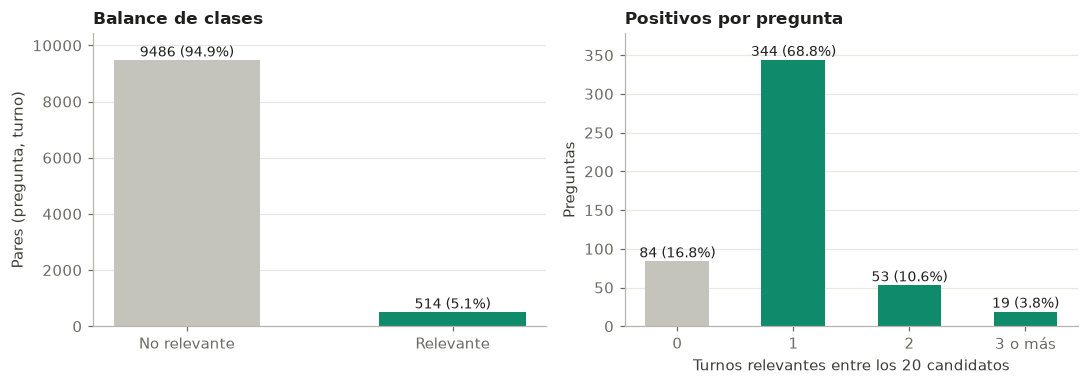

In [14]:
conteo = pares["relevante"].value_counts().sort_index()
# Número de turnos relevantes entre los 20 candidatos de cada pregunta (3 o más se agrupan).
por_pregunta = positivos_por_pregunta.clip(upper=3).value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

ax1.bar([NOMBRE_CLASE[c] for c in conteo.index], conteo.values, color=[COLOR_CLASE[c] for c in conteo.index], width=0.55)
for i, n in enumerate(conteo.values):
    ax1.text(i, n + 120, f"{n} ({n / len(pares):.1%})", ha="center", fontsize=9)
ax1.set_ylabel("Pares (pregunta, turno)")
ax1.set_title("Balance de clases")
ax1.set_ylim(0, conteo.max() * 1.1)
ax1.grid(axis="x", visible=False)

ax2.bar(["0", "1", "2", "3 o más"], por_pregunta.values, color=["#c4c3bc", VERDE, VERDE, VERDE], width=0.55)
for i, n in enumerate(por_pregunta.values):
    ax2.text(i, n + 5, f"{n} ({n / len(positivos_por_pregunta):.1%})", ha="center", fontsize=9)
ax2.set_xlabel("Turnos relevantes entre los 20 candidatos")
ax2.set_ylabel("Preguntas")
ax2.set_title("Positivos por pregunta")
ax2.set_ylim(0, por_pregunta.max() * 1.1)
ax2.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

- Solo 514 de los 10.000 pares son relevantes (5,1%): hay unos 18 negativos por cada positivo. Por eso la exactitud no sirve como métrica y los modelos usan `class_weight="balanced"`.
- El desbalance es propio del problema: de los 20 candidatos de una pregunta, lo normal es que **uno solo** contenga la respuesta (68,8% de las preguntas). Solo el 14,4% tiene dos o más turnos relevantes entre sus candidatos.
- 84 preguntas (16,8%) no tienen ningún positivo: su evidencia quedó fuera del top-20.

### 6.2 Distribución de las features según la clase

Cada panel compara la distribución de una feature en los pares relevantes y en los no relevantes. Las alturas están normalizadas por clase, de modo que se comparan las formas aunque una clase sea 18 veces más grande. Cuanto menos se solapan las dos distribuciones, más útil es la feature por sí sola.

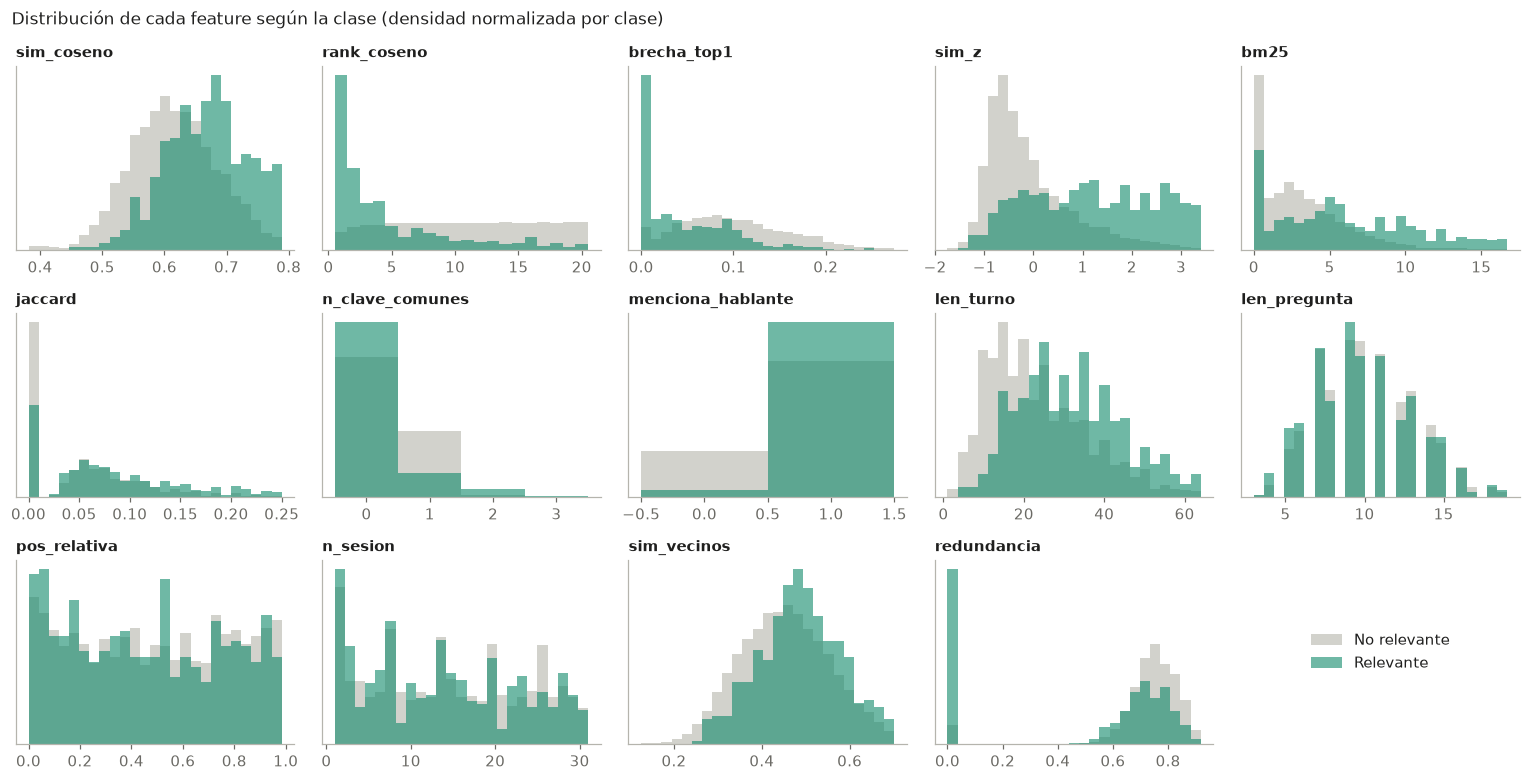

,No relevante (mediana),No relevante (media),Relevante (mediana),Relevante (media)
sim_coseno,0.613,0.616,0.676,0.676
rank_coseno,11.000,10.811,3.000,4.753
brecha_top1,0.096,0.103,0.028,0.045
sim_z,-0.336,-0.080,1.401,1.467
bm25,2.539,3.166,5.858,7.415
jaccard,0.048,0.054,0.071,0.087
n_clave_comunes,0.000,0.337,0.000,0.208
menciona_hablante,1.000,0.749,1.000,0.963
len_turno,21.000,23.753,31.000,32.739
len_pregunta,10.000,10.262,10.000,9.994


In [15]:
fig, ejes = plt.subplots(3, 5, figsize=(14, 7.2))
for ax, f in zip(ejes.flat, FEATURES):
    valores = pares[f]
    # Features con pocos valores distintos: una barra por valor. El resto: 25 intervalos comunes a las dos clases.
    if valores.nunique() <= 20:
        bordes = np.arange(valores.min() - 0.5, valores.max() + 1.5)
    else:
        bordes = np.histogram_bin_edges(valores.clip(upper=valores.quantile(0.99)), bins=25)
    for clase in (0, 1):
        # density=True: cada clase suma 1, así se comparan las formas pese al desbalance.
        ax.hist(valores[pares["relevante"] == clase], bins=bordes, density=True,
                color=COLOR_CLASE[clase], alpha=0.75 if clase == 0 else 0.6, label=NOMBRE_CLASE[clase])
    ax.set_title(f, fontsize=10)
    ax.set_yticks([])
    ax.grid(visible=False)
ejes.flat[-1].axis("off")
handles, labels = ejes.flat[0].get_legend_handles_labels()
ejes.flat[-1].legend(handles, labels, loc="center", fontsize=10)
fig.suptitle("Distribución de cada feature según la clase (densidad normalizada por clase)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

# Mediana y media de cada feature por clase.
resumen_clase = pd.DataFrame({
    f"{NOMBRE_CLASE[clase]} ({nombre})": pares.loc[pares["relevante"] == clase, FEATURES].agg(funcion)
    for clase in (0, 1) for funcion, nombre in [("median", "mediana"), ("mean", "media")]
})
resumen_clase.round(3)

- **Las features relativas a la pregunta son las que más separan.** La mediana de `sim_z` es −0,34 en los no relevantes y 1,40 en los relevantes; la de `rank_coseno` es 11 frente a 3, y la de `brecha_top1` es 0,096 frente a 0,028. Un turno relevante suele estar entre los primeros candidatos de su pregunta.
- **La similitud cruda separa poco.** Las medianas de `sim_coseno` son 0,613 y 0,676, y las dos distribuciones se solapan casi por completo: muchos turnos no relevantes tienen una similitud más alta que turnos relevantes de otras preguntas.
- **Las señales léxicas y de estructura ayudan.** Los turnos relevantes tienen más del doble de `bm25` (mediana de 5,9 frente a 2,5) y son más largos (31 palabras frente a 21). El 96% de los turnos relevantes fue dicho por una persona nombrada en la pregunta, frente al 75% de los no relevantes.
- **`len_pregunta`, `pos_relativa` y `n_sesion` no distinguen las clases:** sus distribuciones son prácticamente iguales. La evidencia aparece en cualquier momento de la conversación.
- **`redundancia` tiene un pico en 0** que no es ruido: el candidato mejor rankeado no tiene a nadie por encima, así que su redundancia vale 0 por construcción. El pico es más alto en los relevantes porque el primer candidato es el que más veces acierta.

### 6.3 Correlaciones

La matriz muestra la correlación de Spearman entre todas las features y con la etiqueta. Sirve para detectar features que repiten la misma información y para ver qué tan fuerte es la relación de cada una con la etiqueta.

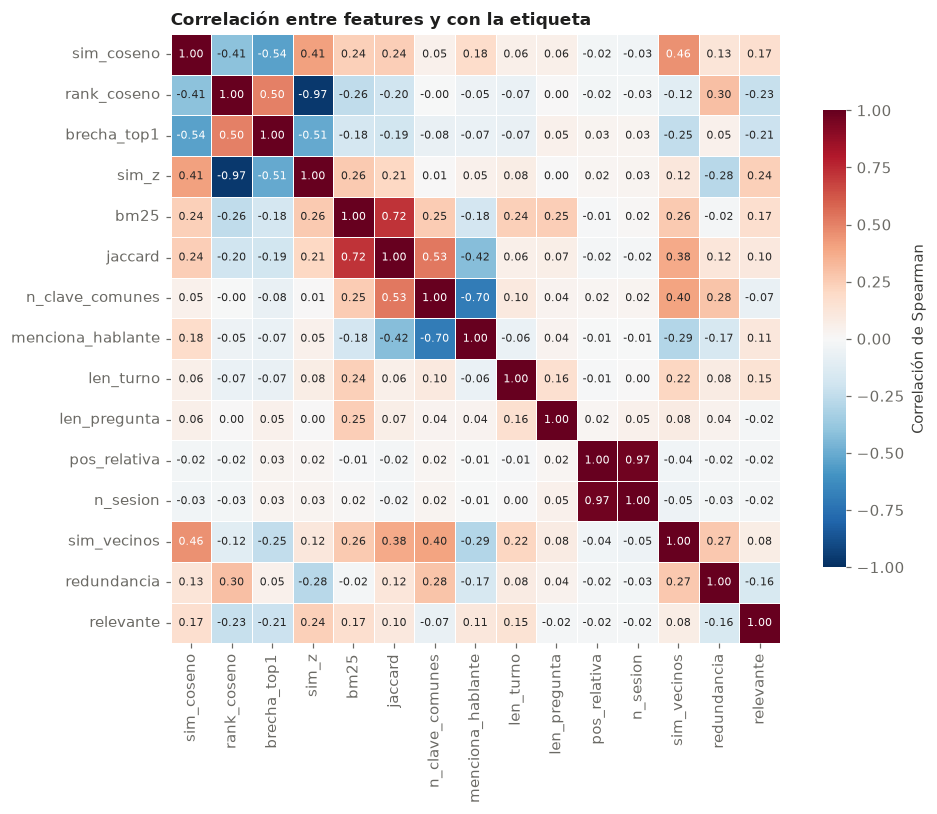

In [16]:
# Spearman: mide relaciones monótonas y no se altera con las escalas tan distintas de las features.
corr = pares[FEATURES + ["relevante"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7.5}, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.75, "label": "Correlación de Spearman"}, ax=ax)
ax.set_title("Correlación entre features y con la etiqueta")
ax.grid(visible=False)
plt.tight_layout()
plt.show()


- **Ninguna feature predice la etiqueta por sí sola.** La correlación más alta con `relevante` es la de `sim_z` (0,24), seguida de `rank_coseno` (−0,23) y `brecha_top1` (−0,21). `sim_coseno` y `bm25` quedan en 0,17. Hace falta combinar señales.
- **Hay pares de features casi duplicadas:** `sim_z` y `rank_coseno` (−0,97), y `pos_relativa` y `n_sesion` (0,97). También `bm25` y `jaccard` van juntas (0,72). En un modelo lineal, el peso se reparte entre las features de cada grupo, así que sus coeficientes no deben leerse por separado.
- **`menciona_hablante` y `n_clave_comunes` se oponen (−0,70).** Cuando la pregunta nombra a quien habla, esa persona se expresa en primera persona y su turno no contiene su propio nombre. Es el mismo fenómeno que llevó a representar cada turno como «hablante: texto».
- **Las señales léxicas aportan información distinta de la semántica:** la correlación de `bm25` con `sim_coseno` y con `sim_z` es de apenas 0,24 y 0,26.

### 6.4 El ranking por similitud y el techo del *retrieval*

Tres vistas de cuánto acierta la similitud por sí sola: la fracción de turnos relevantes en cada posición del ranking, la fracción de preguntas que tienen evidencia entre los *k* primeros candidatos, y esa misma fracción según la categoría de la pregunta. La categoría se usa solo aquí; no es una feature.

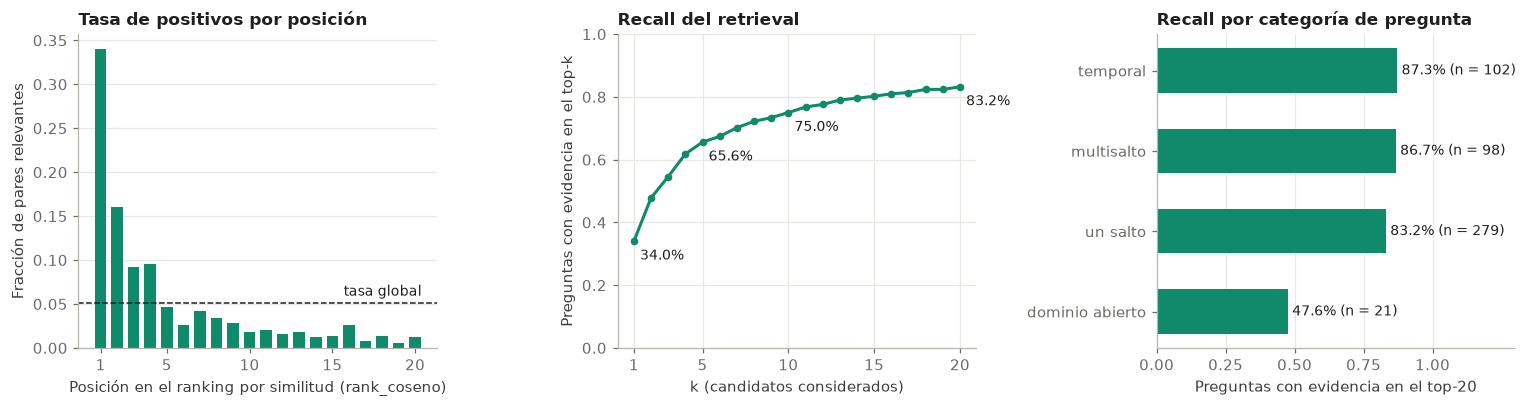

,preguntas,tasa_positivos,recall_top20
categoria,,,
dominio abierto,21,2.9%,47.6%
un salto,279,4.3%,83.2%
multisalto,98,8.2%,86.7%
temporal,102,4.9%,87.3%


In [17]:
tasa_por_rank = pares.groupby("rank_coseno")["relevante"].mean()
# Recall@k: fracción de preguntas con al menos un turno de evidencia entre los k primeros candidatos.
ks = np.arange(1, K_CANDIDATOS + 1)
recall_k = [pares[pares["rank_coseno"] <= k].groupby("id_pregunta")["relevante"].max().sum() / len(preguntas) for k in ks]

por_categoria = pares.groupby("categoria").agg(
    preguntas=("id_pregunta", "nunique"),
    tasa_positivos=("relevante", "mean"),
)
por_categoria["recall_top20"] = (pares.groupby(["categoria", "id_pregunta"])["relevante"].max()
                                 .groupby("categoria").mean())
por_categoria = por_categoria.sort_values("recall_top20")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 3.8))

ax1.bar(tasa_por_rank.index, tasa_por_rank.values, color=VERDE, width=0.7)
ax1.axhline(pares["relevante"].mean(), color="#1f1f1e", linewidth=1, linestyle="--")
ax1.text(20.4, pares["relevante"].mean() + 0.008, "tasa global", ha="right", fontsize=9)
ax1.set_xticks([1, 5, 10, 15, 20])
ax1.set_xlabel("Posición en el ranking por similitud (rank_coseno)")
ax1.set_ylabel("Fracción de pares relevantes")
ax1.set_title("Tasa de positivos por posición")
ax1.grid(axis="x", visible=False)

ax2.plot(ks, recall_k, color=VERDE, marker="o", markersize=4)
for k in (1, 5, 10, 20):
    ax2.annotate(f"{recall_k[k - 1]:.1%}", (k, recall_k[k - 1]), textcoords="offset points", xytext=(4, -12), fontsize=9)
ax2.set_xticks([1, 5, 10, 15, 20])
ax2.set_ylim(0, 1)
ax2.set_xlabel("k (candidatos considerados)")
ax2.set_ylabel("Preguntas con evidencia en el top-k")
ax2.set_title("Recall del retrieval")

ax3.barh(por_categoria.index, por_categoria["recall_top20"], color=VERDE, height=0.55)
for nombre, fila in por_categoria.iterrows():
    ax3.text(fila["recall_top20"] + 0.015, nombre, f"{fila['recall_top20']:.1%} (n = {fila['preguntas']:.0f})", va="center", fontsize=9)
ax3.set_xlim(0, 1.3)
ax3.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax3.set_xlabel("Preguntas con evidencia en el top-20")
ax3.set_title("Recall por categoría de pregunta")
ax3.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

por_categoria.style.format({"tasa_positivos": "{:.1%}", "recall_top20": "{:.1%}"})


- **La similitud ordena bien, pero está lejos de ser suficiente.** El 34,0% de los candidatos en la primera posición es relevante, casi siete veces la tasa global de 5,1%. La tasa cae a 16,0% en la segunda posición y queda por debajo de la global desde la quinta. Aun así, las cuatro primeras posiciones reúnen solo 344 de los 514 positivos (66,9%): un tercio de los turnos relevantes está más abajo, y ahí es donde un clasificador puede aportar.
- **El recall crece cada vez más lento.** Con un solo candidato se cubre el 34,0% de las preguntas; con 5, el 65,6%; con 10, el 75,0%; con 20, el 83,2%. Duplicar los candidatos de 10 a 20 añade solo 8 puntos y duplica los negativos.
- **El 83,2% es el techo de todo el sistema:** en el 16,8% restante ningún clasificador puede acertar, porque la evidencia no está entre los candidatos.
- **Las preguntas de dominio abierto son las más difíciles de recuperar:** solo el 47,6% tiene evidencia en el top-20, frente al 83–87% de las demás categorías. Son pocas (21) y piden inferencias o conocimiento externo, así que su evidencia se parece poco a la pregunta. Las preguntas multisalto tienen la mayor tasa de positivos (8,2%) porque su respuesta está repartida en varios turnos.

## 7. Visualización del espacio de features con t-SNE

t-SNE [7] proyecta datos de muchas dimensiones a dos, intentando que los puntos que eran vecinos en el espacio original sigan siendo vecinos en el plano. Aquí cada punto es un par (pregunta, turno) descrito por sus 14 features estandarizadas, y el color indica la etiqueta.

Tres advertencias para leer el gráfico:

- t-SNE conserva las **vecindades**, no las distancias: el tamaño de los grupos y la separación entre ellos no tienen significado.
- Es una herramienta de visualización. No se usa para entrenar ni para elegir nada.
- El resultado depende de la perplejidad (aquí 30, el valor por defecto) y de la semilla.

Se proyecta una muestra de 150 preguntas completas (3.000 filas). El panel derecho repite el mismo mapa coloreado por `rank_coseno`, para entender qué organiza el espacio.

Filas proyectadas: 3000 | relevantes: 160 (5.3%)


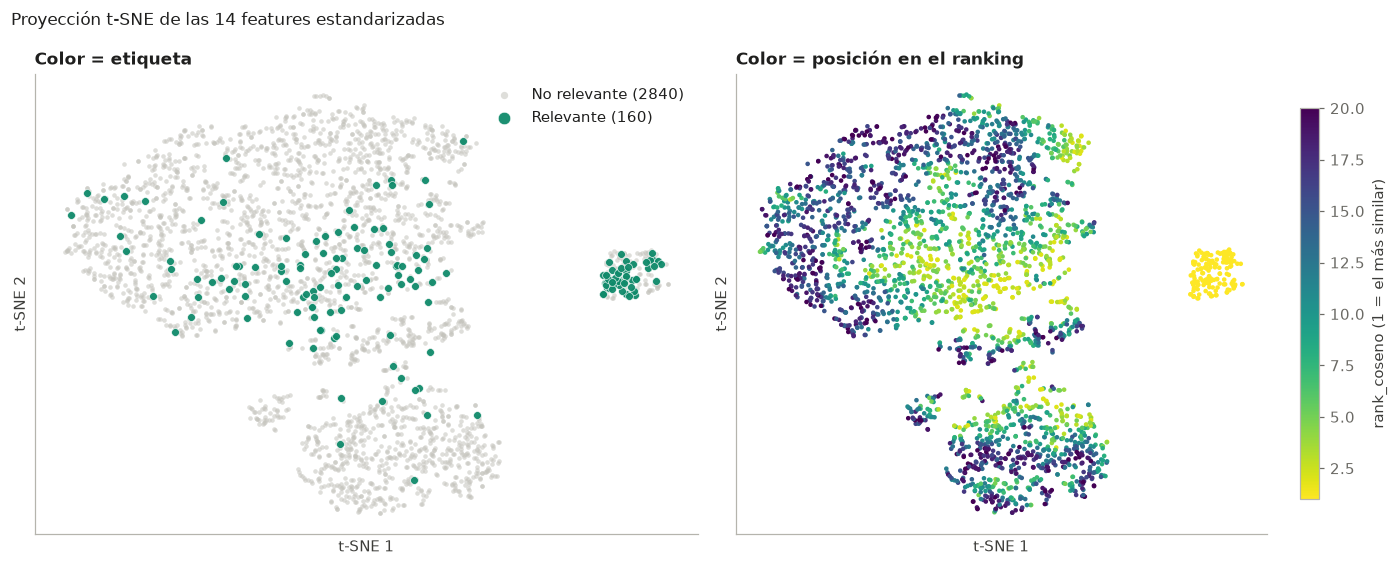

In [18]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Muestra de 150 preguntas completas (3.000 filas): suficiente para ver la estructura y rápido de calcular.
N_PREGUNTAS_TSNE = 150
ids_muestra = np.random.default_rng(SEMILLA).choice(pares["id_pregunta"].unique(), N_PREGUNTAS_TSNE, replace=False)
muestra = pares[pares["id_pregunta"].isin(ids_muestra)].reset_index(drop=True)

# t-SNE trabaja con distancias, así que las features se estandarizan antes.
X_tsne = StandardScaler().fit_transform(muestra[FEATURES])
proyeccion = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
                  random_state=SEMILLA).fit_transform(X_tsne)

print(f"Filas proyectadas: {len(muestra)} | relevantes: {muestra['relevante'].sum()} ({muestra['relevante'].mean():.1%})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))

# Izquierda: color = etiqueta. Los positivos se dibujan al final para que no queden tapados.
for clase, tam, alfa in [(0, 9, 0.55), (1, 26, 0.95)]:
    m = (muestra["relevante"] == clase).to_numpy()
    ax1.scatter(proyeccion[m, 0], proyeccion[m, 1], s=tam, color=COLOR_CLASE[clase], alpha=alfa,
                linewidth=0.4 if clase == 1 else 0, edgecolor="white", label=f"{NOMBRE_CLASE[clase]} ({m.sum()})")
ax1.set_title("Color = etiqueta")
ax1.legend(loc="best", markerscale=1.6)

# Derecha: el mismo mapa, coloreado por la posición del turno en el ranking de similitud.
puntos = ax2.scatter(proyeccion[:, 0], proyeccion[:, 1], s=9, c=muestra["rank_coseno"], cmap="viridis_r", linewidth=0)
fig.colorbar(puntos, ax=ax2, label="rank_coseno (1 = el más similar)", shrink=0.85)
ax2.set_title("Color = posición en el ranking")

for ax in (ax1, ax2):
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(visible=False)
fig.suptitle("Proyección t-SNE de las 14 features estandarizadas", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()


- **Las clases no forman dos grupos separados.** Los turnos relevantes no ocupan una región propia: aparecen mezclados con los no relevantes. Esto concuerda con el análisis exploratorio (ninguna feature separa las clases por sí sola) y anticipa que el problema es difícil: no cabe esperar un PR-AUC cercano a 1.
- **Pero tampoco están repartidos al azar.** Los 10 vecinos más cercanos de un punto relevante son relevantes en un 24% de los casos, frente al 4% para un punto no relevante. Hay estructura que un clasificador puede aprovechar.
- **La isla de la derecha son los candidatos en la primera posición del ranking** (150 puntos, uno por pregunta). Quedan aislados porque comparten valores únicos: `rank_coseno = 1`, `brecha_top1 = 0` y `redundancia = 0`. Es la zona con más positivos (35% de sus puntos), pero aun ahí dos de cada tres no son relevantes.
- **El grupo inferior son los turnos cuyo hablante no se nombra en la pregunta** (`menciona_hablante = 0`). Casi no contiene positivos: 1,2% frente al 4,6% del grupo grande. Una sola feature binaria basta para partir el espacio en dos.
- **Dentro del grupo grande, los positivos se concentran donde el ranking es mejor** (zona clara del panel derecho) y escasean en los bordes, donde están los candidatos peor rankeados.

## 8. Modelos, pipelines y validación

Esta parte lee la tabla desde `data/pares.csv`, así que no hace falta recalcular los embeddings para ejecutarla.

**Modelos.** Se comparan dos clasificadores:

- **Regresión logística**: combina las features de forma lineal. Sus coeficientes se interpretan directamente.
- **Random Forest**: conjunto de árboles de decisión; puede capturar interacciones entre features (por ejemplo, «similitud alta *y además* comparte un nombre propio»).

La comparación responde una pregunta concreta: ¿las señales de relevancia se combinan de forma lineal o hacen falta interacciones? Como referencia se añade la **línea base**: ordenar los candidatos solo por `sim_coseno`, sin entrenar nada.

**Métrica.** Solo el 5% de los pares es relevante, así que la exactitud no sirve: predecir siempre 0 daría 95%. Se usa **PR-AUC** (*average precision*), que resume la curva precisión-recall sin fijar un umbral. Un clasificador al azar obtiene un PR-AUC igual a la tasa de positivos, cerca de 0,05.

**Validación.** Se usa *k-fold* estratificado, agrupado por pregunta y repetido: 10 particiones × 10 repeticiones con semillas distintas = 100 pares entrenamiento/prueba. La misma lista de 100 particiones se usa en la búsqueda de hiperparámetros, en las curvas y en la comparación final.

In [19]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold, cross_val_score,
                                     learning_curve, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEMILLA = 42
K_FOLDS = 10
REPETICIONES = 10      # si tarda demasiado (p. ej. en Colab), usar K_FOLDS = 5 y REPETICIONES = 2
METRICA = "average_precision"

FEATURES = ["sim_coseno", "rank_coseno", "brecha_top1", "sim_z", "bm25", "jaccard",
            "n_clave_comunes", "menciona_hablante", "len_turno", "len_pregunta",
            "pos_relativa", "n_sesion", "sim_vecinos", "redundancia"]

datos = pd.read_csv("data/pares.csv")

# Se reordenan las PREGUNTAS al azar (cada pregunta conserva sus 20 filas juntas).
# Así, cuando la curva de aprendizaje toma "las primeras n filas" de entrenamiento,
# toma preguntas completas de todas las conversaciones y no solo de la primera.
orden = np.random.default_rng(SEMILLA).permutation(datos["id_pregunta"].unique())
datos = datos.set_index("id_pregunta").loc[orden].reset_index()

X = datos[FEATURES]
y = datos["relevante"]
grupos = datos["id_pregunta"]


def folds_repetidos(X, y, grupos, k=K_FOLDS, repeticiones=REPETICIONES):
    # k-fold estratificado y agrupado por pregunta, repetido con distintas semillas.
    for semilla in range(repeticiones):
        cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=semilla)
        yield from cv.split(X, y, grupos)


folds = list(folds_repetidos(X, y, grupos))

# Comprobación: ninguna pregunta aparece a la vez en entrenamiento y en prueba.
assert all(set(grupos.iloc[e]).isdisjoint(grupos.iloc[p]) for e, p in folds)
print(f"Filas: {len(X)} | preguntas: {grupos.nunique()} | positivos: {y.mean():.1%}")
print(f"Particiones: {len(folds)} | filas de prueba por partición: "
      f"{min(len(p) for _, p in folds)} a {max(len(p) for _, p in folds)}")

Filas: 10000 | preguntas: 500 | positivos: 5.1%
Particiones: 100 | filas de prueba por partición: 1000 a 1000


### 8.1 Selección de features: filtro por información mutua

La información mutua mide cuánto se reduce la incertidumbre sobre la etiqueta al conocer una feature; vale 0 si son independientes. Es un método de tipo *filter*: puntúa cada feature contra la etiqueta sin entrenar el clasificador.

El ranking siguiente se calcula con todos los datos y es **solo descriptivo**. La selección que usan los modelos ocurre dentro del pipeline, con los datos de entrenamiento de cada partición.

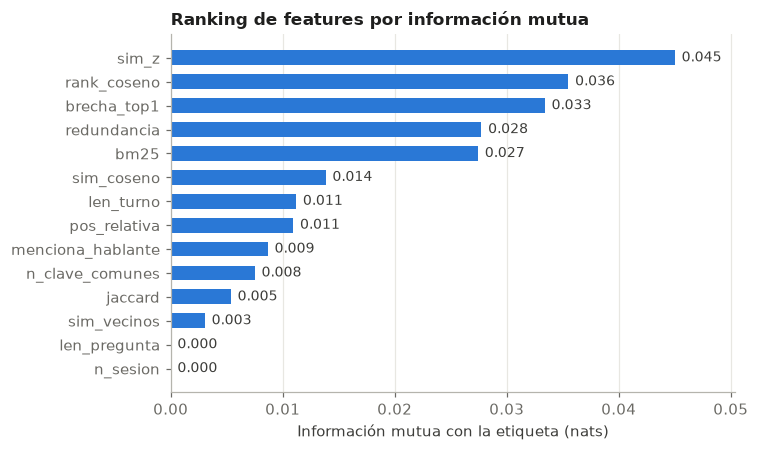

In [20]:
filtro_im = partial(mutual_info_classif, random_state=SEMILLA)

im = pd.Series(filtro_im(StandardScaler().fit_transform(X), y), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(im.index, im.values, color=AZUL, height=0.62)
for nombre, valor in im.items():
    ax.text(valor + 0.0006, nombre, f"{valor:.3f}", va="center", fontsize=9, color="#3d3d3a")
ax.set_xlabel("Información mutua con la etiqueta (nats)")
ax.set_title("Ranking de features por información mutua")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, im.max() * 1.12)
plt.tight_layout()
plt.show()

Las tres features más informativas (`sim_z`, `rank_coseno` y `brecha_top1`) describen lo mismo: qué tan bien queda el turno **frente a los otros candidatos de su pregunta**. Les siguen `redundancia` y `bm25`. La similitud coseno cruda informa bastante menos (0,014) que su versión normalizada `sim_z` (0,045): una similitud de 0,65 puede ser la mejor de una pregunta y una más del montón en otra. `len_pregunta` y `n_sesion` no aportan nada por sí solas.

### 8.2 Pipelines

Cada modelo es un único objeto `Pipeline` de scikit-learn [4] con tres pasos: escalado, filtro de features y clasificador. Al ir todo dentro del pipeline, en cada partición el escalado y la selección se ajustan **solo con los datos de entrenamiento**; los datos de prueba no influyen en ninguna decisión.

El Random Forest no necesita escalado, pero se conserva el mismo esquema para que los dos modelos reciban exactamente el mismo tratamiento. `class_weight="balanced"` penaliza más los errores en la clase minoritaria.

In [21]:
pipe_rl = Pipeline([
    ("escala", StandardScaler()),
    ("filtro", SelectKBest(filtro_im)),
    ("modelo", LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=1000)),
])

pipe_rf = Pipeline([
    ("escala", StandardScaler()),
    ("filtro", SelectKBest(filtro_im)),
    ("modelo", RandomForestClassifier(class_weight="balanced", random_state=SEMILLA)),
])

pipe_rl

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escala', ...), ('filtro', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",functools.par...ndom_state=42)
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",10
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial 

### 8.3 Búsqueda de hiperparámetros

Se prueba una rejilla de valores con `GridSearchCV` y se elige la combinación con mayor PR-AUC promedio en las 100 particiones.

| Modelo | Hiperparámetro | Qué controla |
|---|---|---|
| Ambos | `filtro__k` | Cuántas features deja pasar el filtro |
| Regresión logística | `C` | Inverso de la regularización: valores pequeños regularizan más |
| Regresión logística | `l1_ratio` | Tipo de penalización: 0 = L2 (encoge los coeficientes), 1 = L1 (lleva algunos a cero) |
| Random Forest | `n_estimators` | Número de árboles |
| Random Forest | `max_depth` | Profundidad máxima de cada árbol |
| Random Forest | `min_samples_leaf` | Mínimo de filas por hoja: valores grandes dan árboles más simples |

In [22]:
rejilla_rl = {
    "filtro__k": [4, 6, 8, 10, "all"],
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "modelo__l1_ratio": [0, 1],            # 0 = L2, 1 = L1
}
rejilla_rf = {
    "filtro__k": [6, 10, "all"],
    "modelo__n_estimators": [100, 300],
    "modelo__max_depth": [4, 8, None],
    "modelo__min_samples_leaf": [1, 5, 20],
}

busqueda_rl = GridSearchCV(pipe_rl, rejilla_rl, cv=folds, scoring=METRICA, n_jobs=-1).fit(X, y)
busqueda_rf = GridSearchCV(pipe_rf, rejilla_rf, cv=folds, scoring=METRICA, n_jobs=-1).fit(X, y)

for nombre, b in [("Regresión logística", busqueda_rl), ("Random Forest", busqueda_rf)]:
    print(f"{nombre}: PR-AUC = {b.best_score_:.4f} | {b.best_params_}")

Regresión logística: PR-AUC = 0.4422 | {'filtro__k': 'all', 'modelo__C': 10, 'modelo__l1_ratio': 1}
Random Forest: PR-AUC = 0.4199 | {'filtro__k': 'all', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}


In [23]:
def mejores(busqueda, n=6):
    # Las n mejores combinaciones de la rejilla, con media y desviación entre particiones.
    r = pd.DataFrame(busqueda.cv_results_)
    columnas = [c for c in r.columns if c.startswith("param_")]
    tabla = r.sort_values("rank_test_score")[columnas + ["mean_test_score", "std_test_score"]].head(n)
    tabla.columns = [c.replace("param_", "").replace("modelo__", "").replace("filtro__", "") for c in tabla.columns]
    return tabla.rename(columns={"mean_test_score": "PR-AUC medio", "std_test_score": "desv. est."}).round(4)

display(mejores(busqueda_rl))
display(mejores(busqueda_rf))

,k,C,l1_ratio,PR-AUC medio,desv. est.
57,all,10.0,1,0.4422,0.0616
56,all,10.0,0,0.4422,0.0617
58,all,100.0,0,0.4422,0.0617
59,all,100.0,1,0.4422,0.0617
55,all,1.0,1,0.4421,0.0617
54,all,1.0,0,0.4421,0.0616


,k,max_depth,min_samples_leaf,n_estimators,PR-AUC medio,desv. est.
51,all,None,5,300,0.4199,0.0663
50,all,None,5,100,0.4177,0.0651
45,all,8,5,300,0.4146,0.0655
44,all,8,5,100,0.4139,0.0656
52,all,None,20,100,0.4131,0.0665
46,all,8,20,100,0.4130,0.0678


- **Regresión logística:** PR-AUC de 0,442. A partir de `C = 1` el resultado casi no cambia, y la penalización L1 y la L2 empatan hasta el cuarto decimal. El modelo necesita poca regularización y es insensible a su tipo.
- **Random Forest:** PR-AUC de 0,420 con 300 árboles, sin límite de profundidad y con al menos 5 filas por hoja. Exigir un mínimo de filas por hoja ayuda más que limitar la profundidad.
- **El filtro no descartó ninguna feature:** en los dos modelos gana `k = "all"`. Con solo 14 features, quitar alguna siempre empeoró el resultado. La información mutua puntúa cada feature por separado, y varias que por sí solas informan poco resultan útiles en combinación con las demás, como muestra la tabla siguiente.

### 8.4 Features elegidas y su peso en cada modelo

Con los mejores hiperparámetros, cada pipeline se reajusta con todos los datos. La tabla muestra qué features dejó pasar el filtro y cuánto pesan: el coeficiente en la regresión logística (sobre features estandarizadas, así que son comparables entre sí) y la importancia en el Random Forest.

In [24]:
mejor_rl, mejor_rf = busqueda_rl.best_estimator_, busqueda_rf.best_estimator_

pesos = pd.DataFrame(index=FEATURES)
pesos["información mutua"] = im
pesos.loc[mejor_rl["filtro"].get_support(), "coeficiente RL"] = mejor_rl["modelo"].coef_[0]
pesos.loc[mejor_rf["filtro"].get_support(), "importancia RF"] = mejor_rf["modelo"].feature_importances_
pesos.sort_values("información mutua", ascending=False).round(3)

,información mutua,coeficiente RL,importancia RF
sim_z,0.045,0.641,0.151
rank_coseno,0.036,-0.136,0.121
brecha_top1,0.033,-0.189,0.110
redundancia,0.028,-0.046,0.090
bm25,0.027,0.776,0.090
sim_coseno,0.014,-0.149,0.064
len_turno,0.011,0.550,0.098
pos_relativa,0.011,-0.153,0.043
menciona_hablante,0.009,0.953,0.043
n_clave_comunes,0.008,-0.256,0.021


En la regresión logística los mayores pesos positivos son `menciona_hablante` (+0,95), `bm25` (+0,78), `sim_z` (+0,64), `sim_vecinos` (+0,58) y `len_turno` (+0,55): un turno tiende a ser relevante si lo dijo la persona nombrada en la pregunta, comparte palabras con ella, destaca entre los candidatos, está rodeado de turnos parecidos a la pregunta y es largo. `menciona_hablante` y `sim_vecinos` tenían una información mutua baja, lo que explica por qué el filtro no convenía: su valor aparece al combinarlas.

El Random Forest reparte la importancia de forma parecida al ranking de información mutua, con `sim_z`, `rank_coseno` y `brecha_top1` a la cabeza.

Una precaución: `sim_coseno`, `sim_z`, `rank_coseno` y `brecha_top1` están muy correlacionadas, así que el peso se reparte entre ellas y el coeficiente individual de cada una no debe leerse por separado.

### 8.5 Curva de validación

La curva de validación varía **un** hiperparámetro y deja fijos los demás en su mejor valor. Compara el puntaje en entrenamiento con el de validación:

- Si los dos son bajos, el modelo es demasiado simple (**sesgo**, subajuste).
- Si el de entrenamiento sube y el de validación no, el modelo memoriza (**varianza**, sobreajuste).

Se estudia `C` en la regresión logística y `max_depth` en el Random Forest, porque son los que controlan la complejidad de cada modelo.

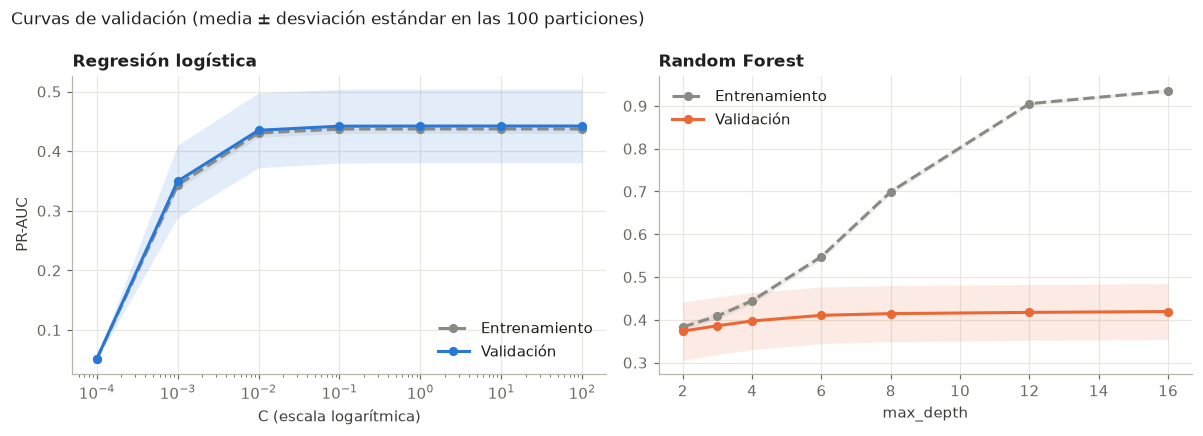

C (escala logarítmica),0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
entrenamiento,0.0514,0.3430,0.4305,0.4371,0.4372,0.4372,0.4372
validación,0.0514,0.3496,0.4350,0.4419,0.4422,0.4422,0.4422


max_depth,2,3,4,6,8,12,16
entrenamiento,0.3832,0.4091,0.4446,0.5477,0.6994,0.9051,0.9351
validación,0.3737,0.3862,0.3974,0.4106,0.4146,0.4174,0.4194


In [25]:
def curva_validacion(ax, estimador, parametro, valores, nombre, etiqueta_x, log=False):
    entreno, valid = validation_curve(estimador, X, y, param_name=parametro, param_range=valores,
                                      cv=folds, scoring=METRICA, n_jobs=-1)
    color = COLOR[nombre]
    for puntajes, estilo, c, texto in [(entreno, "--", GRIS, "Entrenamiento"), (valid, "-", color, "Validación")]:
        media, desv = puntajes.mean(axis=1), puntajes.std(axis=1)
        ax.plot(valores, media, estilo, color=c, marker="o", markersize=5, label=texto)
        ax.fill_between(valores, media - desv, media + desv, color=c, alpha=0.13, linewidth=0)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(etiqueta_x)
    ax.set_title(nombre)
    ax.legend(loc="best")
    return pd.DataFrame({"entrenamiento": entreno.mean(axis=1), "validación": valid.mean(axis=1)},
                        index=pd.Index(valores, name=etiqueta_x)).round(4)


fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
cv_rl = curva_validacion(ejes[0], mejor_rl, "modelo__C", np.logspace(-4, 2, 7),
                         "Regresión logística", "C (escala logarítmica)", log=True)
cv_rf = curva_validacion(ejes[1], mejor_rf, "modelo__max_depth", [2, 3, 4, 6, 8, 12, 16],
                         "Random Forest", "max_depth")
ejes[0].set_ylabel("PR-AUC")
fig.suptitle("Curvas de validación (media ± desviación estándar en las 100 particiones)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()
display(cv_rl.T, cv_rf.T)



- **Regresión logística:** con `C = 0,0001` la regularización es tan fuerte que el modelo no aprende nada y obtiene 0,051, lo mismo que el azar (subajuste). El puntaje sube hasta `C = 0,1` y después se mantiene en 0,442. Las curvas de entrenamiento y validación van juntas en todo el rango: el modelo no sobreajusta.
- **Random Forest:** al aumentar la profundidad, el puntaje en entrenamiento pasa de 0,38 a 0,94, mientras que en validación apenas sube de 0,37 a 0,42. Esa separación es sobreajuste: los árboles profundos memorizan los datos de entrenamiento. Aun así la validación no empeora, porque promediar muchos árboles amortigua el efecto.

### 8.6 Curva de aprendizaje

La curva de aprendizaje entrena cada modelo con cantidades crecientes de datos y mide el PR-AUC en entrenamiento y en validación. Responde si conseguir más datos ayudaría:

- Si la curva de validación **sigue subiendo** al final, faltan datos (domina la varianza).
- Si ya está **plana** y cerca de la de entrenamiento, el modelo llegó a su techo (domina el sesgo): harían falta mejores features, no más filas.

Cada 20 filas equivalen a una pregunta.

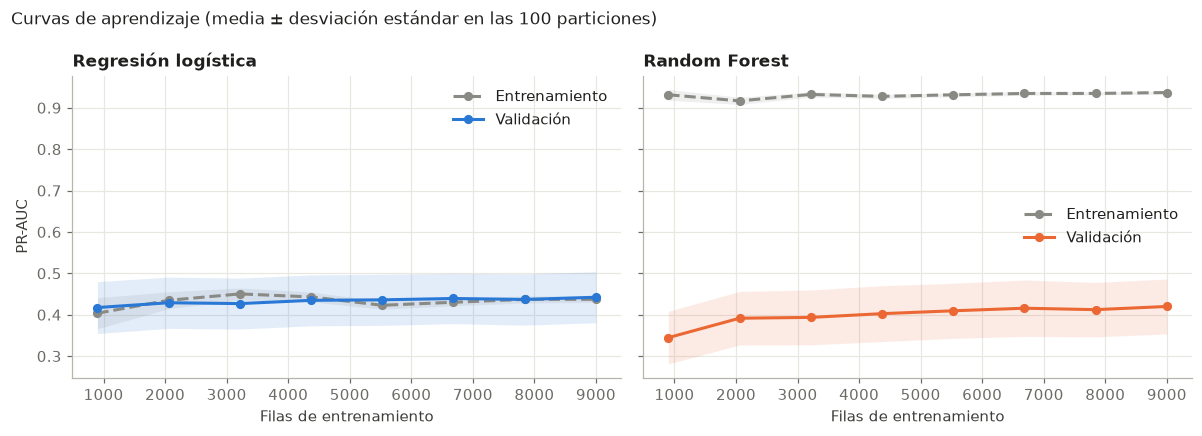

filas,900,2057,3214,4371,5528,6685,7842,9000
entrenamiento,0.4036,0.4349,0.4503,0.4430,0.4228,0.4301,0.4370,0.4372
validación,0.4173,0.4289,0.4269,0.4347,0.4360,0.4392,0.4369,0.4422


filas,900,2057,3214,4371,5528,6685,7842,9000
entrenamiento,0.9314,0.9167,0.9322,0.9276,0.9314,0.9346,0.9347,0.9368
validación,0.3446,0.3915,0.3935,0.4025,0.4095,0.4157,0.4122,0.4199


In [26]:
def curva_aprendizaje(ax, estimador, nombre):
    tamanos, entreno, valid = learning_curve(estimador, X, y, train_sizes=np.linspace(0.1, 1.0, 8),
                                             cv=folds, scoring=METRICA, n_jobs=-1, shuffle=False)
    color = COLOR[nombre]
    for puntajes, estilo, c, texto in [(entreno, "--", GRIS, "Entrenamiento"), (valid, "-", color, "Validación")]:
        media, desv = puntajes.mean(axis=1), puntajes.std(axis=1)
        ax.plot(tamanos, media, estilo, color=c, marker="o", markersize=5, label=texto)
        ax.fill_between(tamanos, media - desv, media + desv, color=c, alpha=0.13, linewidth=0)
    ax.set_xlabel("Filas de entrenamiento")
    ax.set_title(nombre)
    ax.legend(loc="best")
    return pd.DataFrame({"entrenamiento": entreno.mean(axis=1), "validación": valid.mean(axis=1)},
                        index=pd.Index(tamanos, name="filas")).round(4)


fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ca_rl = curva_aprendizaje(ejes[0], mejor_rl, "Regresión logística")
ca_rf = curva_aprendizaje(ejes[1], mejor_rf, "Random Forest")
ejes[0].set_ylabel("PR-AUC")
fig.suptitle("Curvas de aprendizaje (media ± desviación estándar en las 100 particiones)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()
display(ca_rl.T, ca_rf.T)


- **Regresión logística:** con solo 900 filas (45 preguntas) ya alcanza 0,417, y con las 9.000 llega a 0,442. Las dos curvas están juntas y casi planas: el modelo llegó a su **techo** (domina el sesgo). Más preguntas del mismo tipo no lo mejorarían; harían falta features nuevas.
- **Random Forest:** la validación sube de 0,345 a 0,420 y todavía no se aplana, con una distancia enorme respecto al entrenamiento (0,94). Aquí domina la **varianza**: el modelo sí se beneficiaría de más datos. Con los datos disponibles, sin embargo, queda por debajo de la regresión logística en todos los tamaños.

## 9. Comparación estadística

Los dos modelos, ya con sus mejores hiperparámetros, se evalúan en **exactamente las mismas 100 particiones**. Cada partición da un PR-AUC por modelo, así que los puntajes forman 100 parejas. Se incluyen dos líneas base que no entrenan nada y se evalúan en las mismas particiones:

- **`sim_coseno`**: la similitud tal cual, que es lo que usa un sistema de recuperación estándar.
- **`sim_z`**: la misma similitud, pero normalizada dentro de los 20 candidatos de cada pregunta. Es una línea base más exigente, porque el valor absoluto de la similitud no es comparable entre preguntas.

Sobre esas parejas se aplica el **test de Wilcoxon de rangos con signo**, pareado y no paramétrico, habitual para comparar clasificadores [5]: compara las diferencias partición a partición sin asumir que siguen una distribución normal.

- Hipótesis nula: los dos modelos tienen el mismo desempeño.
- Se rechaza si el valor p es menor que 0,05.

In [27]:
puntajes = pd.DataFrame({
    "Línea base (sim_coseno)": [average_precision_score(y.iloc[p], X["sim_coseno"].iloc[p]) for _, p in folds],
    "Línea base (sim_z)": [average_precision_score(y.iloc[p], X["sim_z"].iloc[p]) for _, p in folds],
    "Regresión logística": cross_val_score(mejor_rl, X, y, cv=folds, scoring=METRICA, n_jobs=-1),
    "Random Forest": cross_val_score(mejor_rf, X, y, cv=folds, scoring=METRICA, n_jobs=-1),
})

resumen = puntajes.agg(["mean", "std", "median", "min", "max"]).T
resumen.columns = ["media", "desv. est.", "mediana", "mínimo", "máximo"]
print(f"PR-AUC en {len(folds)} particiones (un clasificador al azar obtendría {y.mean():.3f})")
resumen.round(4)

PR-AUC en 100 particiones (un clasificador al azar obtendría 0.051)


,media,desv. est.,mediana,mínimo,máximo
Línea base (sim_coseno),0.1758,0.0548,0.1653,0.0883,0.4154
Línea base (sim_z),0.3250,0.0593,0.3239,0.2090,0.4742
Regresión logística,0.4422,0.0620,0.4417,0.3005,0.5704
Random Forest,0.4199,0.0667,0.4249,0.2703,0.6015


In [28]:
def comparar(a, b):
    # Wilcoxon pareado de b contra a, con el tamaño de la diferencia.
    d = puntajes[b] - puntajes[a]
    w = stats.wilcoxon(puntajes[b], puntajes[a])
    # Test t corregido de Nadeau y Bengio: corrige que las particiones repetidas no son independientes.
    n = len(d)
    razon = np.mean([len(p) / len(e) for e, p in folds])          # n_prueba / n_entrenamiento
    t = d.mean() / np.sqrt((1 / n + razon) * d.var(ddof=1))
    return {
        "comparación": f"{b} − {a}",
        "diferencia media": d.mean(),
        "diferencia mediana": d.median(),
        "particiones ganadas": f"{(d > 0).sum()} de {n}",
        "p Wilcoxon": w.pvalue,
        "p t corregido": 2 * stats.t.sf(abs(t), df=n - 1),
    }


pruebas = pd.DataFrame([
    comparar("Regresión logística", "Random Forest"),
    comparar("Línea base (sim_coseno)", "Regresión logística"),
    comparar("Línea base (sim_coseno)", "Random Forest"),
    comparar("Línea base (sim_z)", "Regresión logística"),
    comparar("Línea base (sim_z)", "Random Forest"),
]).set_index("comparación")
pruebas.style.format({"diferencia media": "{:+.4f}", "diferencia mediana": "{:+.4f}",
                      "p Wilcoxon": "{:.2e}", "p t corregido": "{:.2e}"})

,diferencia media,diferencia mediana,particiones ganadas,p Wilcoxon,p t corregido
comparación,,,,,
Random Forest − Regresión logística,-0.0223,-0.0209,28 de 100,1.90e-07,9.50e-02
Regresión logística − Línea base (sim_coseno),+0.2665,+0.2559,100 de 100,3.90e-18,3.60e-21
Random Forest − Línea base (sim_coseno),+0.2442,+0.2471,100 de 100,3.90e-18,1.55e-20
Regresión logística − Línea base (sim_z),+0.1173,+0.1217,99 de 100,4.02e-18,2.20e-10
Random Forest − Línea base (sim_z),+0.0950,+0.0944,98 de 100,4.27e-18,3.36e-09


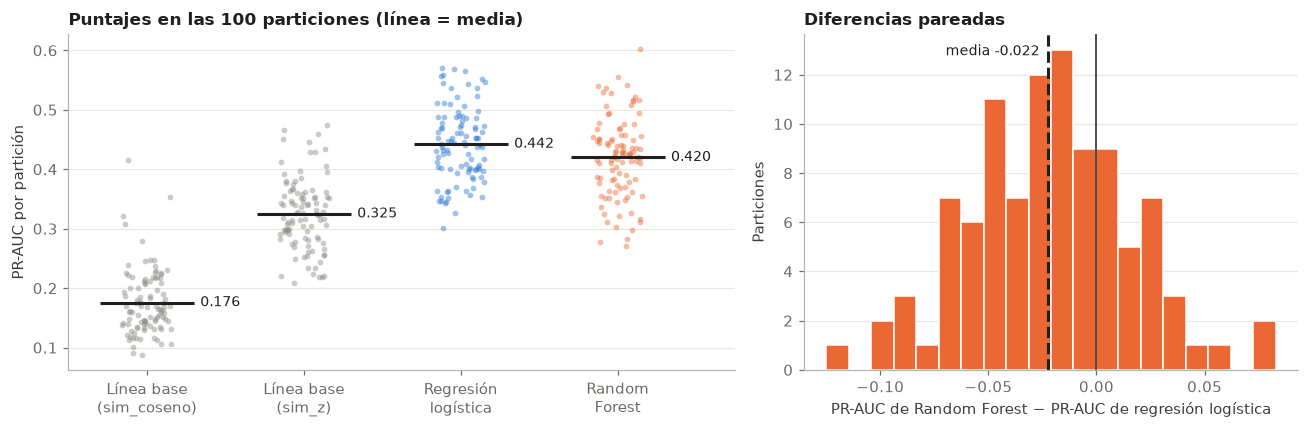

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.35, 1]})

# Izquierda: los 100 puntajes de cada modelo.
rng = np.random.default_rng(SEMILLA)
for i, nombre in enumerate(puntajes.columns):
    valores = puntajes[nombre]
    ax1.scatter(i + rng.uniform(-0.16, 0.16, len(valores)), valores, s=14, color=COLOR[nombre], alpha=0.45, linewidth=0)
    ax1.hlines(valores.mean(), i - 0.3, i + 0.3, color="#1f1f1e", linewidth=2)
    ax1.text(i + 0.34, valores.mean(), f"{valores.mean():.3f}", va="center", fontsize=9)
ax1.set_xticks(range(4), ["Línea base\n(sim_coseno)", "Línea base\n(sim_z)", "Regresión\nlogística", "Random\nForest"])
ax1.set_xlim(-0.5, 3.75)
ax1.set_ylabel("PR-AUC por partición")
ax1.set_title("Puntajes en las 100 particiones (línea = media)")
ax1.grid(axis="x", visible=False)

# Derecha: diferencias pareadas entre los dos modelos.
d = puntajes["Random Forest"] - puntajes["Regresión logística"]
ax2.hist(d, bins=20, color=NARANJA, edgecolor="white", linewidth=1)
ax2.axvline(0, color="#1f1f1e", linewidth=1)
ax2.axvline(d.mean(), color="#1f1f1e", linewidth=2, linestyle="--")
ax2.text(d.mean() - 0.004, ax2.get_ylim()[1] * 0.97, f"media {d.mean():+.3f}", va="top", ha="right", fontsize=9)
ax2.set_xlabel("PR-AUC de Random Forest − PR-AUC de regresión logística")
ax2.set_ylabel("Particiones")
ax2.set_title("Diferencias pareadas")
ax2.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### 9.1 Qué dicen los resultados

**Los dos modelos superan con claridad a la similitud sola.** La regresión logística obtiene un PR-AUC medio de 0,442 y el Random Forest 0,420, frente a 0,176 de `sim_coseno` y 0,325 de `sim_z`. Los dos ganan a `sim_coseno` en las 100 particiones y a `sim_z` en 99 (regresión logística) y 98 (Random Forest); en los cuatro casos el test de Wilcoxon y el test t corregido rechazan la hipótesis nula (p < 0,001). Combinar señales léxicas, de estructura y de contexto con la similitud aporta información que la similitud no tiene.

**Normalizar la similitud ya da casi la mitad de la mejora.** Pasar de `sim_coseno` a `sim_z`, sin entrenar nada, sube el PR-AUC de 0,176 a 0,325. Buena parte de la debilidad de la similitud cruda viene de que sus valores no son comparables entre preguntas.

**La regresión logística supera al Random Forest, pero por poco.** La diferencia media es de 0,022 puntos de PR-AUC a favor de la regresión logística, que gana en 72 de las 100 particiones. El test de Wilcoxon rechaza la hipótesis nula (p ≈ 2 × 10⁻⁷).

**Esa significancia debe leerse con cautela.** Las 100 particiones no son independientes: los conjuntos de entrenamiento de un *k-fold* repetido se solapan, y eso hace que el valor p de Wilcoxon sea optimista. El test t corregido de Nadeau y Bengio [6], que tiene en cuenta ese solapamiento, da p ≈ 0,095 y **no** rechaza la hipótesis nula. La conclusión prudente es que la regresión logística es al menos tan buena como el Random Forest, y que la diferencia de 0,022 es pequeña frente a la variación entre particiones (desviación estándar de 0,06).

**Respuesta a la pregunta del proyecto.** No hay evidencia de que hagan falta interacciones entre features: un modelo lineal, más simple e interpretable, iguala o supera al no lineal. Además, la curva de aprendizaje indica que la regresión logística ya llegó a su techo, así que la mejora futura debe venir de nuevas features y no de más datos ni de un modelo más complejo.

**Limitaciones.**

- Los hiperparámetros se eligieron con las mismas particiones que luego se usan para comparar, lo que favorece ligeramente a ambos modelos frente a las líneas base.
- La evaluación usa preguntas nuevas sobre conversaciones ya vistas; con solo 10 conversaciones no se midió la generalización a conversaciones nuevas.
- El 16,8% de las preguntas no tiene ningún turno de evidencia entre sus 20 candidatos. Ningún clasificador puede recuperarlas: el recall del *retrieval* es el techo de todo el sistema.

## 10. Conclusiones

1. **Un clasificador que combina varias señales recupera mejor que la similitud sola.** La regresión logística alcanza un PR-AUC medio de 0,442, dos veces y media el de ordenar por `sim_coseno` (0,176), y la supera en las 100 particiones. La diferencia es significativa tanto con el test de Wilcoxon como con el test t corregido (p < 0,001).

2. **Importa más la posición relativa de un turno que su similitud absoluta.** Normalizar la similitud dentro de los candidatos de cada pregunta (`sim_z`), sin entrenar nada, sube el PR-AUC de 0,176 a 0,325. Las tres features más informativas según la información mutua (`sim_z`, `rank_coseno`, `brecha_top1`) describen esa posición relativa, y en el mapa de t-SNE los candidatos en primera posición forman un grupo aparte donde el 35% es relevante.

3. **Lo que la similitud no ve lo aportan señales sencillas.** Las features con mayor peso en la regresión logística son `menciona_hablante` (+0,95) y `bm25` (+0,78). Cuando la pregunta nombra a quien dijo el turno, la tasa de relevantes es de 6,5%; cuando no, de 0,8%.

4. **No se encontró evidencia de que haga falta un modelo no lineal.** La regresión logística supera al Random Forest por 0,022 puntos de PR-AUC y gana en 72 de las 100 particiones. El test de Wilcoxon rechaza la igualdad, pero el test t corregido por el solapamiento entre particiones no (p ≈ 0,095). Con este resultado no se puede afirmar que un modelo sea mejor que el otro; se prefiere la regresión logística por ser más simple e interpretable.

5. **El filtro de features no eliminó ninguna.** En los dos modelos, la mejor configuración conserva las 14 features. Varias con información mutua casi nula, como `menciona_hablante` y `sim_vecinos`, tienen coeficientes altos al combinarse con las demás: un filtro que evalúa cada feature por separado no detecta ese aporte.

6. **Más datos del mismo tipo no mejorarían la regresión logística.** Su curva de aprendizaje es casi plana: pasa de 0,417 con 45 preguntas a 0,442 con 450, con entrenamiento y validación juntos. El Random Forest, en cambio, sobreajusta (0,94 en entrenamiento frente a 0,42 en validación) y su curva de validación todavía sube.

7. **El *retrieval* limita todo el sistema.** En el 16,8% de las preguntas ningún turno de evidencia llega a los 20 candidatos, y en las de dominio abierto esa cifra supera la mitad. Ahí el clasificador no puede hacer nada.

**Trabajo futuro.** Los resultados señalan tres pasos: mejorar la etapa de recuperación (por ejemplo, combinando la búsqueda por embeddings con BM25), diseñar features nuevas en lugar de reunir más preguntas, y validar agrupando por conversación para medir la generalización a conversaciones que el modelo nunca vio.

## Referencias

[1] A. Maharana, D.-H. Lee, S. Tulyakov, M. Bansal, F. Barbieri e Y. Fang, «Evaluating Very Long-Term Conversational Memory of LLM Agents», en *Proc. 62nd Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2024.

[2] Y. Zhang *et al.*, «Qwen3 Embedding: Advancing Text Embedding and Reranking Through Foundation Models», arXiv:2506.05176, 2025.

[3] S. Robertson y H. Zaragoza, «The Probabilistic Relevance Framework: BM25 and Beyond», *Found. Trends Inf. Retr.*, vol. 3, n.º 4, pp. 333-389, 2009.

[4] F. Pedregosa *et al.*, «Scikit-learn: Machine Learning in Python», *J. Mach. Learn. Res.*, vol. 12, pp. 2825-2830, 2011.

[5] J. Demšar, «Statistical Comparisons of Classifiers over Multiple Data Sets», *J. Mach. Learn. Res.*, vol. 7, pp. 1-30, 2006.

[6] C. Nadeau e Y. Bengio, «Inference for the Generalization Error», *Mach. Learn.*, vol. 52, n.º 3, pp. 239-281, 2003.

[7] L. van der Maaten y G. Hinton, «Visualizing Data using t-SNE», *J. Mach. Learn. Res.*, vol. 9, pp. 2579-2605, 2008.

[8] M. L. Waskom, «seaborn: statistical data visualization», *J. Open Source Softw.*, vol. 6, n.º 60, art. 3021, 2021.

[9] Anthropic, *Claude Code*. [En línea]. Disponible: https://claude.com/claude-code. Accedido: 21 de noviembre de 2026.

Se usó Claude Code [9] como asistente de IA para escribir parte del código y revisar la redacción del notebook.